# 03 · Sequências temporais + LSTM no SAML-D

Experimento **separado** (não sobrescreve `analysis.ipynb` nem `model_completo.ipynb`) para testar uma hipótese:

> **Hipótese H1.** O histórico recente de transações de uma mesma conta remetente fornece contexto que ajuda a decidir
> se a transação atual é suspeita — além dos atributos da transação isolada.

É uma hipótese **a testar**, não uma promessa. Se a LSTM ficar abaixo do LightGBM, o resultado continua sendo válido
desde que a metodologia esteja correta.

### Como ler este notebook
Cada seção traz: (1) *o que* é feito, (2) *por quê*, (3) o código, (4) *o que olhar* na saída. Marquei três tipos de afirmação:

| Marca | Significado |
|---|---|
| ✅ **Confirmado** | consta nos arquivos `SAML-D.md` / notebooks da equipe |
| 🧠 **Decisão/hipótese** | escolha de modelagem a ser defendida e testada (ex.: tamanho da janela) |
| ❓ **Verificar** | o notebook confere nos dados antes de usar |

### Fatos confirmados nos materiais (✅)
* ~9.504.852 transações; 9.873 positivas (≈0,104 %); período 2022-10-07 → 2023-08-23; 0 timestamps inválidos.
* Partições cronológicas 70/15/15 (treino 6.653.396 · validação 1.425.728 · teste 1.425.728) — **as mesmas** do `model_completo.ipynb`,
  para que os **registros-alvo sejam idênticos** e a comparação seja justa.
* Resultados de referência (LightGBM no teste: P=0,901 · R=0,836 · F1=0,867 · AP=0,920) estão no `SAML-D.md`.

### O que **não** foi definido pelo professor (🧠)
Tamanho da janela, intervalo, agrupamento, número de janelas. Tudo isso é **hipótese experimental** aqui e será comparado (L = 1, 5, 10, 20).

## 1. Importações e configuração

In [ ]:
import copy
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

import torch
import torch.nn as nn
from torch.utils.data import (BatchSampler, DataLoader, Dataset, RandomSampler,
                              SequentialSampler, WeightedRandomSampler)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ------------------------------ configuração --------------------------------
CAMINHO_CSV = "SAML-D.csv"
NROWS_DEV = None                 # ex.: 1_000_000 para teste rápido (primeiras transações no tempo)
SEMENTE = 42
ALVO = "Is_laundering"
ENTIDADE = "Sender_account"      # 🧠 entidade que agrupa as sequências (justificada na seção 4)
PROP_TREINO, PROP_VAL = 0.70, 0.15

TAMANHO_REF = 10                 # 🧠 L usado para comparar estratégias de balanceamento
TAMANHOS = [1, 5, 10, 20]        # 🧠 L=1 = ablação "sem histórico"

# --- rede / treino
HIDDEN, N_CAMADAS, DROPOUT, EMB_DIM = 64, 1, 0.2, 4
LR, EPOCAS, PACIENCIA = 1e-3, 6, 2
BATCH_TREINO, BATCH_AVAL = 512, 8192

# --- amostras (o treino completo tem 6,6 M alvos: não cabe em uma época de CPU)
N_TREINO_NATURAL = 500_000       # baseline / pos_weight (mesmo tamanho usado nos modelos de árvore)
N_NEG_UNDER = 150_000            # undersampling: todas as positivas + N negativas
AMOSTRAS_POR_EPOCA = 200_000     # WeightedRandomSampler
MAX_VAL_EPOCA = 300_000          # subconjunto (natural) da validação usado a cada época

np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
DISPOSITIVO = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
    else "cpu"
)
print("Dispositivo:", DISPOSITIVO, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.0+cu126


## 2. Leitura e inspeção dos dados

Mesma leitura do `model_completo.ipynb` (`Laundering_type` **não** é lida: só é conhecida depois do fato → vazamento).
Ordenação: `Date` + `Time` → `Timestamp`, ordenação **estável** por `Timestamp` e `reset_index`. Assim o índice `0…N-1`
é a posição cronológica e as partições coincidem com as dos modelos de árvore.

In [2]:
COLUNAS_LEITURA = ["Time", "Date", "Sender_account", "Receiver_account", "Amount", "Payment_currency",
                   "Received_currency", "Sender_bank_location", "Receiver_bank_location",
                   "Payment_type", "Is_laundering"]

dataset = pd.read_csv(
    CAMINHO_CSV, usecols=COLUNAS_LEITURA, nrows=NROWS_DEV,
    dtype={"Sender_account": "int64", "Receiver_account": "int64", "Is_laundering": "int8"},
)
dataset["Timestamp"] = pd.to_datetime(dataset["Date"].astype(str) + " " + dataset["Time"].astype(str), errors="coerce")

n_invalidos = int(dataset["Timestamp"].isna().sum())
n_fora_de_ordem = int((dataset["Timestamp"].diff().dt.total_seconds() < 0).sum())   # ANTES de ordenar
print("Timestamps inválidos:", n_invalidos)
print("Transições fora de ordem no arquivo original:", n_fora_de_ordem,
      "(0 = o arquivo já vinha cronológico; mesmo assim ordenamos explicitamente)")

dataset = (dataset.dropna(subset=["Timestamp"]).drop(columns=["Date", "Time"])
           .sort_values("Timestamp", kind="stable").reset_index(drop=True))

N = len(dataset)
print("\nDimensões:", dataset.shape, "| positivas:", int(dataset[ALVO].sum()), f"({dataset[ALVO].mean():.4%})")
print("Período:", dataset["Timestamp"].min(), "→", dataset["Timestamp"].max())
display(dataset.head())

Timestamps inválidos: 0
Transições fora de ordem no arquivo original: 0 (0 = o arquivo já vinha cronológico; mesmo assim ordenamos explicitamente)

Dimensões: (9504852, 10) | positivas: 9873 (0.1039%)
Período: 2022-10-07 10:35:19 → 2023-08-23 10:57:12


,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Timestamp
0,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,2022-10-07 10:35:19
1,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,2022-10-07 10:35:20
2,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,2022-10-07 10:35:20
3,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,2022-10-07 10:35:21
4,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,2022-10-07 10:35:21


## 3. Auditoria de timestamps, IDs e alvo (❓ → verificado)

Antes de definir qualquer sequência precisamos saber:

1. **Timestamps repetidos** — transações no mesmo segundo têm ordem relativa indefinida; vamos medir quantas.
2. **O ID da conta é utilizável?** `Sender_account` é numérico, tem quantas contas, quantas transações por conta?
   Se a maioria das contas tiver 1–2 transações, o histórico será curto (e isso muda a interpretação).
3. **Conta remetente também aparece como destinatária?** (define se "histórico de envios" captura toda a atividade da conta).
4. **Alvo** — apenas valores 0/1, sem ausentes.

> ⚠️ **Os IDs de conta NÃO entram como atributo.** Eles só servem para *agrupar* o histórico. Usá-los como atributo permitiria
> à rede memorizar contas (atalho artificial).

In [3]:
print("Valores do alvo:", dataset[ALVO].value_counts(dropna=False).to_dict())
print("Ausentes por coluna:\n", dataset.isna().sum().to_string(), "\n")

ts = dataset["Timestamp"]
print(f"Timestamps repetidos (global): {ts.duplicated().sum():,} ({ts.duplicated().mean():.2%})")
print(f"Mesmo remetente + mesmo timestamp: {dataset.duplicated([ENTIDADE, 'Timestamp']).sum():,}")

contagem = dataset.groupby(ENTIDADE).size()
print(f"\nContas remetentes distintas: {len(contagem):,} | destinatárias distintas: {dataset['Receiver_account'].nunique():,}")
print(f"Remetentes que também aparecem como destinatárias: "
      f"{np.isin(contagem.index.values, dataset['Receiver_account'].unique()).mean():.1%}")
print("\nTransações por conta remetente:")
display(contagem.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_frame("transações"))

pos_por_conta = dataset.groupby(ENTIDADE)[ALVO].sum()
print(f"Contas com ≥1 transação positiva: {(pos_por_conta > 0).sum():,} ({(pos_por_conta > 0).mean():.2%} das contas)")

Valores do alvo: {0: 9494979, 1: 9873}
Ausentes por coluna:
 Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Timestamp                 0 

Timestamps repetidos (global): 1,750,941 (18.42%)
Mesmo remetente + mesmo timestamp: 3,387

Contas remetentes distintas: 292,715 | destinatárias distintas: 652,266
Remetentes que também aparecem como destinatárias: 30.6%

Transações por conta remetente:


,transações
count,292715.0
mean,32.5
std,91.6
min,1.0
25%,9.0
50%,12.0
75%,12.0
90%,14.0
95%,233.0
99%,506.0


Contas com ≥1 transação positiva: 4,950 (1.69% das contas)


## 4. Definição da sequência (🧠 decisões que você deve saber defender)

**Entidade.** `Sender_account` (conta remetente). *Por quê:* o objetivo é capturar o **comportamento de envio** de uma conta
(recorrência, mudança de valor, rajadas). Misturar contas diferentes numa mesma sequência criaria um histórico artificial.
Alternativa a testar no futuro: histórico por conta **destinatária** (detectar contas que recebem de muitos) ou por par remetente→destinatário.

**Rótulo.** Cada exemplo é uma **transação-alvo** `T(t)`. Entrada = as últimas `L` transações **da mesma conta, até `T(t)` inclusive**.
Alvo = `Is_laundering` de `T(t)` — *não* "qualquer positivo na janela".

```
conta A:   T1   T2   T3   T4   T5   T6   T7 ...
L = 5      └────────────────┘            alvo = T5   (entrada [T1..T5])
              └────────────────┘         alvo = T6   (entrada [T2..T6])
```

**Stride 1 / todo registro é alvo uma vez.** Cada transação do dataset é alvo exatamente uma vez → mesmos alvos dos modelos de árvore
(**1.425.728** no teste). As janelas se sobrepõem no *contexto*, mas **o mesmo registro-alvo nunca está em duas partições**.

**Histórico curto (início da conta).** Se a conta tem menos de `L-1` transações anteriores, a janela é preenchida com **zeros à esquerda**
e um canal extra `mascara` (1 = transação real, 0 = preenchimento). Assim nenhuma transação é descartada e os alvos continuam idênticos.

**Histórico pode atravessar partições?** Sim, **somente para trás no tempo**: um alvo da validação pode usar transações de contas que
ocorreram no período de treino, porque, no mundo real, esse histórico existiria naquele instante. O que é proibido: informação **futura** e **rótulos**
(nem o `Is_laundering` do histórico é usado — em produção o rótulo só chega depois de uma investigação).

**Atributos por passo** (derivados da transação; nenhuma agregação futura):
`Amount_log`, `dia_mes`, `hora_sin/cos`, `semana_sin/cos`, `operacao_internacional`, `mudanca_moeda`,
`dt_log` (segundos desde o envio anterior da mesma conta, em log) e `sem_anterior` (1 se for o primeiro envio da conta) + 5 categóricas via *embedding*.

> **Diferença para os modelos de árvore:** lá usamos One-Hot e agregados "somente passado" calculados por nós (`envios_anteriores_log`, `pares_anteriores_log`…).
> Aqui a LSTM precisa **aprender** isso a partir da janela. Por isso a rede usa **embeddings** (compactos para sequências) e **não** recebe esses agregados.

## 5. Divisão temporal (definida **antes** de qualquer ajuste de transformação)

Mesma regra do `model_completo.ipynb`: `int(N·0,70)` e `int(N·0,85)` sobre os dados **ordenados no tempo**.
Como o índice já é a posição cronológica, os alvos de cada partição são simplesmente intervalos de índices.

In [4]:
i_tr, i_val = int(N * PROP_TREINO), int(N * (PROP_TREINO + PROP_VAL))
alvos_treino = np.arange(0, i_tr, dtype=np.int64)
alvos_val = np.arange(i_tr, i_val, dtype=np.int64)
alvos_teste = np.arange(i_val, N, dtype=np.int64)

y_all = dataset[ALVO].to_numpy(dtype=np.int8)
resumo_part = pd.DataFrame({
    "alvos": [len(alvos_treino), len(alvos_val), len(alvos_teste)],
    "positivos": [int(y_all[a].sum()) for a in (alvos_treino, alvos_val, alvos_teste)],
    "início": [dataset["Timestamp"].iloc[a[0]] for a in (alvos_treino, alvos_val, alvos_teste)],
    "fim": [dataset["Timestamp"].iloc[a[-1]] for a in (alvos_treino, alvos_val, alvos_teste)],
}, index=["Treino", "Validação", "Teste"])
resumo_part["taxa_%"] = resumo_part["positivos"] / resumo_part["alvos"] * 100
display(resumo_part)

# Conferência com os números registrados no SAML-D.md (só faz sentido com o arquivo completo)
REGISTRADO = {"Treino": (6_653_396, 6_764), "Validação": (1_425_728, 1_412), "Teste": (1_425_728, 1_697)}
if NROWS_DEV is None:
    for nome, (n_reg, p_reg) in REGISTRADO.items():
        ok = (resumo_part.loc[nome, "alvos"] == n_reg) and (resumo_part.loc[nome, "positivos"] == p_reg)
        print(f"{nome:<10s} {'✅ igual ao registrado' if ok else '⚠️ DIFERENTE do registrado'}  ({n_reg:,} / {p_reg:,})")
else:
    print("NROWS_DEV ativo: conferência com os valores registrados ignorada.")

,alvos,positivos,início,fim,taxa_%
Treino,6653396,6764,2022-10-07 10:35:19,2023-05-18 19:28:03,0.101662
Validação,1425728,1412,2023-05-18 19:28:03,2023-07-05 15:24:39,0.099037
Teste,1425728,1697,2023-07-05 15:24:42,2023-08-23 10:57:12,0.119027


Treino     ✅ igual ao registrado  (6,653,396 / 6,764)
Validação  ✅ igual ao registrado  (1,425,728 / 1,412)
Teste      ✅ igual ao registrado  (1,425,728 / 1,697)


## 6. Pré-processamento (ajustado **somente** no treino)

* `StandardScaler` nas numéricas — `fit` apenas nas linhas do treino (`[0, i_tr)`), `transform` em todas.
* Categóricas → **códigos inteiros** com o vocabulário do treino. Categoria nunca vista no treino → código `0` (desconhecida). O código `0`
  também é o "preenchimento": o `Embedding(padding_idx=0)` mantém esse vetor em zero.
* Para sequências guardamos **uma linha por transação** (matriz `F_num` e `F_cat`) e montamos as janelas **sob demanda**
  (seção 7) — materializar todas as janelas custaria ≈ `N·L·d·4` bytes (≈ 8 GB para L=20 no dataset completo).

In [5]:
colunas_num_seq = ["Amount_log", "dia_mes", "hora_sin", "hora_cos", "semana_sin", "semana_cos",
                   "operacao_internacional", "mudanca_moeda", "dt_log", "sem_anterior"]
colunas_cat_seq = ["Payment_type", "Payment_currency", "Received_currency",
                   "Sender_bank_location", "Receiver_bank_location"]
assert ALVO not in colunas_num_seq + colunas_cat_seq, "o alvo não pode ser atributo!"


def features_por_transacao(df):
    # Atributos de UMA transação (+ tempo desde o envio anterior da mesma conta: só passado).
    t = df["Timestamp"]
    hora, dow = t.dt.hour, t.dt.dayofweek
    dt = df.groupby(ENTIDADE, sort=False)["Timestamp"].diff().dt.total_seconds()      # NaN no 1º envio
    num = pd.DataFrame(index=df.index)
    num["Amount_log"] = np.log1p(df["Amount"]).astype("float32")
    num["dia_mes"] = t.dt.day.astype("float32")
    num["hora_sin"] = np.sin(2 * np.pi * hora / 24).astype("float32")
    num["hora_cos"] = np.cos(2 * np.pi * hora / 24).astype("float32")
    num["semana_sin"] = np.sin(2 * np.pi * dow / 7).astype("float32")
    num["semana_cos"] = np.cos(2 * np.pi * dow / 7).astype("float32")
    num["operacao_internacional"] = (df["Sender_bank_location"] != df["Receiver_bank_location"]).astype("float32")
    num["mudanca_moeda"] = (df["Payment_currency"] != df["Received_currency"]).astype("float32")
    num["dt_log"] = np.log1p(dt.fillna(0)).astype("float32")
    num["sem_anterior"] = dt.isna().astype("float32")
    return num[colunas_num_seq]


num_df = features_por_transacao(dataset)

# --- escalonamento: fit SOMENTE no treino
escalonador = StandardScaler().fit(num_df.iloc[:i_tr])
F_num = escalonador.transform(num_df).astype(np.float32)          # (N, 10)
del num_df

# --- categóricas: vocabulário do treino; 0 = desconhecida/preenchimento
vocab = {c: pd.Index(dataset[c].iloc[:i_tr].unique()) for c in colunas_cat_seq}
F_cat = np.stack(
    [(pd.Categorical(dataset[c], categories=vocab[c]).codes.astype(np.int16) + 1) for c in colunas_cat_seq], axis=1
)                                                                  # (N, 5) int16
cardinalidades = [len(vocab[c]) + 1 for c in colunas_cat_seq]

print("F_num:", F_num.shape, F_num.dtype, f"{F_num.nbytes / 1e6:,.0f} MB")
print("F_cat:", F_cat.shape, F_cat.dtype, f"{F_cat.nbytes / 1e6:,.0f} MB")
print("Cardinalidades (inclui 0 = desconhecida):", dict(zip(colunas_cat_seq, cardinalidades)))
print("Categorias do val/teste fora do vocabulário do treino:",
      {c: int((F_cat[i_tr:, j] == 0).sum()) for j, c in enumerate(colunas_cat_seq)})

F_num: (9504852, 10) float32 380 MB
F_cat: (9504852, 5) int16 95 MB
Cardinalidades (inclui 0 = desconhecida): {'Payment_type': 8, 'Payment_currency': 14, 'Received_currency': 14, 'Sender_bank_location': 19, 'Receiver_bank_location': 19}
Categorias do val/teste fora do vocabulário do treino: {'Payment_type': 0, 'Payment_currency': 0, 'Received_currency': 0, 'Sender_bank_location': 0, 'Receiver_bank_location': 0}


## 7. Estrutura que monta as janelas sob demanda

Para cada transação precisamos dos índices das `L` últimas transações **da mesma conta**. Truque sem loops:

1. `order = argsort(conta, estável)` → linhas agrupadas por conta e, **dentro da conta, em ordem cronológica** (porque o índice já é cronológico);
2. `rank[i]` = posição da linha `i` em `order`;
3. `pos_grupo[i]` = nº de transações **anteriores** da mesma conta (0 = primeira);
4. as linhas da janela do alvo `i` são `order[rank[i]-L+1 : rank[i]+1]`, e as posições com `pos_grupo + deslocamento < 0` são preenchimento.

`obter_lote` faz isso **vetorizado** para um lote inteiro de alvos. Saídas e dimensões (B = lote, L = tamanho, d = nº de atributos numéricos + 1 máscara):

| Saída | Dimensão | Conteúdo |
|---|---|---|
| `Xn` | `(B, L, d=11)` | numéricas escalonadas + canal `mascara` |
| `Xc` | `(B, L, 5)` | códigos das categóricas (int64) |
| `y` | `(B,)` | `Is_laundering` da **última** transação |

In [6]:
class ContextoSequencias:
    # Guarda matrizes por transação e monta janelas por conta sem materializá-las.
    def __init__(self, F_num, F_cat, y, codigos_conta, pos_grupo):
        self.F_num, self.F_cat, self.y = F_num, F_cat, y
        self.N = len(y)
        self.order = np.argsort(codigos_conta, kind="stable")             # grupos por conta, cronológicos
        self.rank = np.empty(self.N, dtype=np.int64)
        self.rank[self.order] = np.arange(self.N)
        self.pos_grupo = pos_grupo.astype(np.int64)                        # transações anteriores da conta

    def obter_lote(self, idx, L):
        idx = np.asarray(idx, dtype=np.int64)
        desl = np.arange(-L + 1, 1, dtype=np.int64)                        # (L,)  ex.: [-4,-3,-2,-1,0]
        real = (self.pos_grupo[idx][:, None] + desl[None, :]) >= 0         # (B,L) True = transação real
        pos = np.clip(self.rank[idx][:, None] + desl[None, :], 0, self.N - 1)
        linhas = self.order[pos]                                           # (B,L) índices globais
        Xn = self.F_num[linhas]                                            # (B,L,dn) (cópia)
        Xc = self.F_cat[linhas].astype(np.int64)                           # (B,L,5)
        Xn[~real] = 0.0
        Xc[~real] = 0
        Xn = np.concatenate([Xn, real[..., None].astype(np.float32)], axis=-1)   # + canal máscara
        return Xn, Xc, self.y[idx].astype(np.float32), linhas, real


codigos_conta = pd.factorize(dataset[ENTIDADE])[0]
pos_grupo = dataset.groupby(ENTIDADE, sort=False).cumcount().to_numpy()
ctx = ContextoSequencias(F_num, F_cat, y_all, codigos_conta, pos_grupo)

mem_lazy = (F_num.nbytes + F_cat.nbytes + ctx.order.nbytes + ctx.rank.nbytes + ctx.pos_grupo.nbytes) / 1e9
print(f"Memória (sob demanda): {mem_lazy:.2f} GB")
for L_ in TAMANHOS:
    print(f"  se materializássemos todas as janelas com L={L_:>2d}: {N * L_ * (F_num.shape[1] + 1 + 5) * 4 / 1e9:6.1f} GB")

Memória (sob demanda): 0.70 GB
  se materializássemos todas as janelas com L= 1:    0.6 GB
  se materializássemos todas as janelas com L= 5:    3.0 GB
  se materializássemos todas as janelas com L=10:    6.1 GB
  se materializássemos todas as janelas com L=20:   12.2 GB


### 7.1 Verificações de *leakage* e de dimensões (rode **antes** de treinar)

Testes automáticos em uma amostra de alvos. Se qualquer `assert` falhar, **não treine** — a sequência está errada.

* a **última** posição de cada janela é a própria transação-alvo;
* nenhuma linha da janela é **posterior** ao alvo (índice ou timestamp);
* todas as linhas reais da janela pertencem à **mesma conta**;
* nº de passos reais = `min(L, transações anteriores + 1)`;
* o rótulo `y` vem do alvo (não da janela); `Is_laundering` não está nas colunas de entrada;
* partições disjuntas e em ordem cronológica.

In [7]:
ts_ns = dataset["Timestamp"].to_numpy().astype("datetime64[ns]").astype(np.int64)


def verificar_sequencias(ctx, alvos, L, n=3000, semente=SEMENTE):
    rng = np.random.default_rng(semente)
    idx = rng.choice(alvos, size=min(n, len(alvos)), replace=False)
    Xn, Xc, y, linhas, real = ctx.obter_lote(idx, L)
    B = len(idx)
    assert Xn.shape == (B, L, F_num.shape[1] + 1) and Xc.shape == (B, L, F_cat.shape[1]) and y.shape == (B,)
    assert (linhas[:, -1] == idx).all(), "a última posição deve ser o alvo"
    assert real[:, -1].all(), "o alvo é sempre real"
    assert (linhas[real.nonzero()] <= np.repeat(idx, real.sum(1))).all(), "linha futura na janela (índice)"
    alvo_ts = np.repeat(ts_ns[idx], real.sum(1))
    assert (ts_ns[linhas[real]] <= alvo_ts).all(), "linha futura na janela (timestamp)"
    conta_alvo = np.repeat(codigos_conta[idx], real.sum(1))
    assert (codigos_conta[linhas[real]] == conta_alvo).all(), "janela mistura contas diferentes"
    assert (real.sum(1) == np.minimum(L, ctx.pos_grupo[idx] + 1)).all(), "nº de passos reais incorreto"
    if L > 1:
        ambos = real[:, 1:] & real[:, :-1]
        assert (np.diff(linhas, axis=1)[ambos] > 0).all(), "janela fora de ordem cronológica"
    assert (y == y_all[idx]).all(), "rótulo deve ser o do alvo"
    assert (Xn[~real][:, :-1] == 0).all() and (Xc[~real] == 0).all(), "preenchimento deve ser zero"
    return True


for L_ in TAMANHOS:
    for nome, a in [("treino", alvos_treino), ("validação", alvos_val), ("teste", alvos_teste)]:
        verificar_sequencias(ctx, a, L_)
print("✅ janelas OK para L =", TAMANHOS, "em treino/validação/teste")

# partições
assert len(np.intersect1d(alvos_treino, alvos_val)) == 0 and len(np.intersect1d(alvos_val, alvos_teste)) == 0
assert alvos_treino.max() < alvos_val.min() and alvos_val.max() < alvos_teste.min()
assert ts_ns[alvos_treino].max() <= ts_ns[alvos_val].min() and ts_ns[alvos_val].max() <= ts_ns[alvos_teste].min()
print("✅ partições disjuntas e cronológicas (treino < validação < teste)")


def exemplo_sequencia(idx_alvo, L):
    # Mostra, em formato legível, a janela de um alvo (para você conferir e explicar na banca).
    _, _, _, linhas, real = ctx.obter_lote([idx_alvo], L)
    linhas = linhas[0][real[0]]
    return dataset.loc[linhas, ["Timestamp", ENTIDADE, "Receiver_account", "Amount", "Payment_type",
                                "Sender_bank_location", "Receiver_bank_location", ALVO]]


candidatos = alvos_val[(y_all[alvos_val] == 1) & (pos_grupo[alvos_val] >= 6)]
if len(candidatos):
    print(f"\nExemplo (L=6): alvo = última linha (índice {candidatos[0]}). Só a última linha define o rótulo.")
    display(exemplo_sequencia(int(candidatos[0]), 6))

✅ janelas OK para L = [1, 5, 10, 20] em treino/validação/teste
✅ partições disjuntas e cronológicas (treino < validação < teste)

Exemplo (L=6): alvo = última linha (índice 6653497). Só a última linha define o rótulo.


,Timestamp,Sender_account,Receiver_account,Amount,Payment_type,Sender_bank_location,Receiver_bank_location,Is_laundering
4162326,2023-02-24 08:02:07,1715501381,2299704124,165.94,Cash Withdrawal,UK,UK,0
5346821,2023-04-04 21:12:12,1715501381,2299704124,190.98,Cash Withdrawal,UK,UK,0
5374107,2023-04-05 19:27:44,1715501381,2299704124,186.62,Cash Withdrawal,UK,UK,0
5461482,2023-04-08 18:27:59,1715501381,2299704124,115.84,Cash Withdrawal,UK,UK,0
6149074,2023-05-01 17:03:53,1715501381,2299704124,214.14,Cash Withdrawal,UK,UK,0
6653497,2023-05-18 19:31:13,1715501381,6919638030,60679.20,Credit card,UK,UK,1


## 8. EDA das sequências

Perguntas que os gráficos respondem:

1. **Classes dos alvos** por partição (é a mesma proporção de ~0,1 %? mudou no teste?).
2. **Cobertura de histórico:** para cada `L`, que fração dos alvos tem a janela completa? Se a maioria das contas tiver pouco histórico,
   janelas grandes (`L=20`) terão quase só preenchimento — e não devemos esperar muito delas.
3. **Positivas têm histórico mais curto/longo que negativas?** (indício se o histórico pode ajudar).
4. **Distribuição temporal** dos positivos (há deriva ao longo do tempo?).
5. **Sequências por entidade:** quantas transações por conta.

> Os gráficos descrevem os dados; **não provam** que a LSTM vai funcionar nem explicam *por que* uma transação é suspeita.

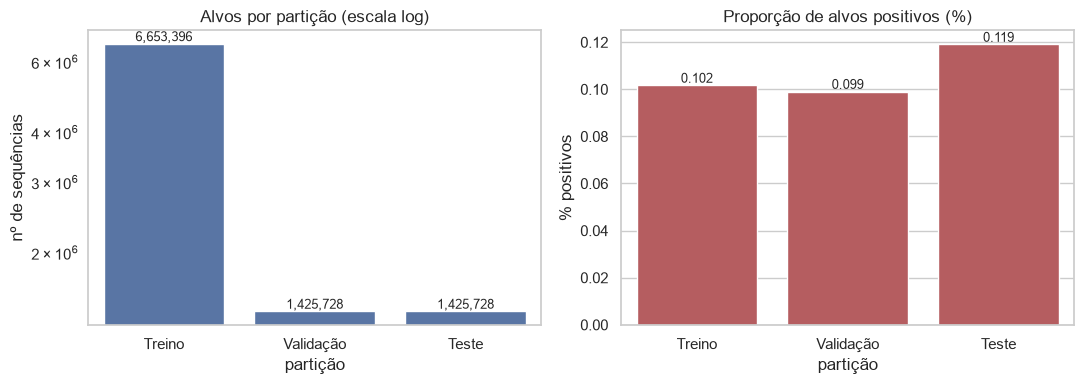

,partição,L,janela_completa_%,positivos_com_janela_completa_%,taxa_positiva_completa_%,taxa_positiva_incompleta_%
0,Treino,1,100.000,100.000,0.102,NaN
1,Treino,5,87.898,75.370,0.087,0.207
2,Treino,10,75.476,60.201,0.081,0.165
3,Treino,20,66.252,45.520,0.070,0.164
4,Validação,1,100.000,100.000,0.099,NaN
5,Validação,5,90.575,96.459,0.105,0.037
6,Validação,10,78.709,87.465,0.110,0.058
7,Validação,20,71.230,69.405,0.096,0.105
8,Teste,1,100.000,100.000,0.119,NaN
9,Teste,5,91.182,96.759,0.126,0.044


In [8]:
def grafico_classes_por_particao():
    df_ = resumo_part.reset_index().rename(columns={"index": "partição"})
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.barplot(data=df_, x="partição", y="alvos", ax=ax[0], color="#4C72B0")
    ax[0].set_yscale("log"); ax[0].set_title("Alvos por partição (escala log)"); ax[0].set_ylabel("nº de sequências")
    sns.barplot(data=df_, x="partição", y="taxa_%", ax=ax[1], color="#C44E52")
    ax[1].set_title("Proporção de alvos positivos (%)"); ax[1].set_ylabel("% positivos")
    for a, col in zip(ax, ["alvos", "taxa_%"]):
        for p, v in zip(a.patches, df_[col]):
            a.annotate(f"{v:,.3f}" if col == "taxa_%" else f"{int(v):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                       ha="center", va="bottom", fontsize=9)
    plt.tight_layout(); plt.show()


def tabela_cobertura_historico(tamanhos=TAMANHOS):
    linhas_ = []
    for nome, a in [("Treino", alvos_treino), ("Validação", alvos_val), ("Teste", alvos_teste)]:
        for L_ in tamanhos:
            completa = pos_grupo[a] >= (L_ - 1)
            yy = y_all[a]
            linhas_.append({"partição": nome, "L": L_, "janela_completa_%": completa.mean() * 100,
                            "positivos_com_janela_completa_%": (completa[yy == 1].mean() * 100) if yy.sum() else np.nan,
                            "taxa_positiva_completa_%": (yy[completa].mean() * 100) if completa.any() else np.nan,
                            "taxa_positiva_incompleta_%": (yy[~completa].mean() * 100) if (~completa).any() else np.nan})
    return pd.DataFrame(linhas_)


grafico_classes_por_particao()
cobertura = tabela_cobertura_historico()
display(cobertura.round(3))

fig = px.bar(cobertura, x="L", y="janela_completa_%", color="partição", barmode="group",
             title="Fração de alvos com janela completa (sem preenchimento), por L",
             labels={"janela_completa_%": "% de alvos"})
fig.update_layout(template="plotly_white"); fig.show()

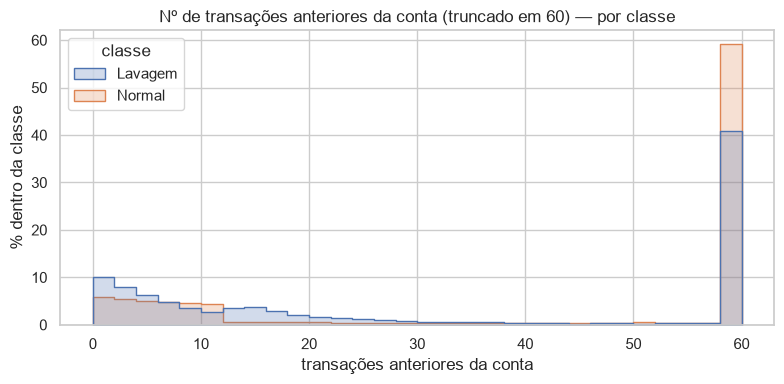

,mes,total,positivos,taxa,taxa_%
0,2022-10,708654,694,0.0010,0.0979
1,2022-11,897621,794,0.0009,0.0885
2,2022-12,900341,907,0.0010,0.1007
3,2023-01,908320,940,0.0010,0.1035
4,2023-02,904806,946,0.0010,0.1046
5,2023-03,908562,927,0.0010,0.1020
6,2023-04,902883,962,0.0011,0.1065
7,2023-05,917601,866,0.0009,0.0944
8,2023-06,897243,1024,0.0011,0.1141
9,2023-07,902239,983,0.0011,0.1090


In [9]:
# 3) Histórico de positivas vs negativas (nº de transações anteriores da conta) — amostra leve
rng_h = np.random.default_rng(SEMENTE)
idx_pos = np.flatnonzero(y_all == 1)
idx_neg = rng_h.choice(np.flatnonzero(y_all == 0), size=min(200_000, int((y_all == 0).sum())), replace=False)
amostra_hist = pd.DataFrame({
    "anteriores": np.minimum(pos_grupo[np.r_[idx_pos, idx_neg]], 60),
    "classe": ["Lavagem"] * len(idx_pos) + ["Normal"] * len(idx_neg),
})
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=amostra_hist, x="anteriores", hue="classe", stat="percent", common_norm=False, bins=30, element="step", ax=ax)
ax.set(title="Nº de transações anteriores da conta (truncado em 60) — por classe", xlabel="transações anteriores da conta", ylabel="% dentro da classe")
plt.tight_layout(); plt.show()

# 5) Transações por conta remetente (agregado antes de plotar: não embutimos 855 mil pontos no notebook)
freq_contas = contagem.clip(upper=200).value_counts().sort_index()
fig = px.bar(x=freq_contas.index, y=freq_contas.values, log_y=True,
             title="Transações por conta remetente (truncado em 200; eixo y em log)",
             labels={"x": "transações da conta", "y": "nº de contas"})
fig.update_layout(template="plotly_white"); fig.show()

# 4) Distribuição temporal dos alvos
mensal = (dataset.groupby(dataset["Timestamp"].dt.to_period("M"))[ALVO].agg(total="count", positivos="sum", taxa="mean")
          .rename_axis("mes").reset_index())
mensal["mes"] = mensal["mes"].astype(str)
mensal["taxa_%"] = mensal["taxa"] * 100
fig = go.Figure()
fig.add_bar(x=mensal["mes"], y=mensal["positivos"], name="positivos", marker_color="#C44E52")
fig.add_scatter(x=mensal["mes"], y=mensal["taxa_%"], name="taxa (%)", yaxis="y2", mode="lines+markers", line=dict(color="black"))
fig.update_layout(title="Positivos por mês e taxa positiva (%)", template="plotly_white",
                  yaxis=dict(title="nº de positivos"), yaxis2=dict(title="taxa (%)", overlaying="y", side="right", showgrid=False))
fig.show()
display(mensal.round(4))

## 9. Dataset e DataLoader (montagem **sob demanda**)

* `SequenciasSAML.__getitem__` recebe uma **lista de posições** (um lote inteiro) e devolve os três tensores do lote — evita o *overhead*
  de montar 512 exemplos um a um em Python.
* O `DataLoader` usa `batch_size=None` (sem *auto-collation*) e um `BatchSampler` que decide **quais** alvos entram:
  * `SequentialSampler` → avaliação (ordem preservada);
  * `RandomSampler` → treino embaralhado;
  * `WeightedRandomSampler` → treino balanceado **apenas no treino** (seção 11).
* `num_workers=0`: as matrizes ficam compartilhadas na memória do processo principal (cópias por worker custariam GB).

In [10]:
class SequenciasSAML(Dataset):
    def __init__(self, ctx, alvos, L):
        self.ctx, self.alvos, self.L = ctx, np.asarray(alvos, dtype=np.int64), L

    def __len__(self):
        return len(self.alvos)

    def __getitem__(self, posicoes):                       # posicoes = lista de posições (um lote)
        idx = self.alvos[np.asarray(posicoes)]
        Xn, Xc, y, _, _ = self.ctx.obter_lote(idx, self.L)
        return torch.from_numpy(Xn), torch.from_numpy(Xc), torch.from_numpy(y)


def criar_loader(ds, batch_size, modo="sequencial", pesos=None, n_amostras=None, semente=SEMENTE):
    g = torch.Generator().manual_seed(semente)
    if modo == "sequencial":
        base = SequentialSampler(ds)
    elif modo == "embaralhado":
        base = RandomSampler(ds, generator=g)
    elif modo == "ponderado":
        base = WeightedRandomSampler(torch.as_tensor(pesos, dtype=torch.double), num_samples=n_amostras,
                                     replacement=True, generator=g)      # limite do torch.multinomial: 2^24 itens
    else:
        raise ValueError(modo)
    return DataLoader(ds, sampler=BatchSampler(base, batch_size=batch_size, drop_last=False), batch_size=None, num_workers=0)

### 9.1 Inspeção de um lote real (dimensões)

In [11]:
# Inspeção de um lote real
_ds = SequenciasSAML(ctx, alvos_treino[:5000], L=10)
xn, xc, yb = next(iter(criar_loader(_ds, 32, "sequencial")))
print("Xn:", tuple(xn.shape), xn.dtype, "→ (batch, L, atributos numéricos + máscara)")
print("Xc:", tuple(xc.shape), xc.dtype, "→ (batch, L, categóricas)")
print("y :", tuple(yb.shape), yb.dtype, "→ (batch,)  rótulo da ÚLTIMA transação")

Xn: (32, 10, 11) torch.float32 → (batch, L, atributos numéricos + máscara)
Xc: (32, 10, 5) torch.int64 → (batch, L, categóricas)
y : (32,) torch.float32 → (batch,)  rótulo da ÚLTIMA transação


## 10. Arquitetura (pequena, com *baseline* primeiro)

```
Xc (B,L,5) ──Embedding(emb_dim=4) por coluna──► (B,L,20) ┐
                                                          ├─ concat → (B,L,31) ─► LSTM(hidden=64) ─► h do ÚLTIMO passo (B,64)
Xn (B,L,11) ──────────────────────────────────────────────┘                          ─► Dropout ─► Linear(64→1) ─► logit (B,)
```

* **Por que o último passo?** O alvo é a última transação; com preenchimento **à esquerda**, o último passo sempre é uma transação real e já "viu" toda a janela.
* **Loss:** `BCEWithLogitsLoss` (sigmoid + entropia cruzada binária de forma estável). A rede devolve **logit**; a probabilidade é `sigmoid(logit)`.
* **Capacidade pequena** (1 camada, 64 unidades, dropout 0,2) para ter um baseline defensável antes de qualquer arquitetura maior.

In [12]:
class ClassificadorLSTM(nn.Module):
    def __init__(self, n_num, cardinalidades, emb_dim=EMB_DIM, hidden=HIDDEN, n_camadas=N_CAMADAS, dropout=DROPOUT):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, emb_dim, padding_idx=0) for c in cardinalidades])
        d_in = n_num + emb_dim * len(cardinalidades)
        self.lstm = nn.LSTM(d_in, hidden, num_layers=n_camadas, batch_first=True,
                            dropout=dropout if n_camadas > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.saida = nn.Linear(hidden, 1)

    def forward(self, x_num, x_cat):
        emb = torch.cat([e(x_cat[..., i]) for i, e in enumerate(self.embs)], dim=-1)     # (B,L,5*emb)
        x = torch.cat([x_num, emb], dim=-1)                                                # (B,L,d_in)
        saida, _ = self.lstm(x)                                                            # (B,L,hidden)
        return self.saida(self.drop(saida[:, -1, :])).squeeze(-1)                          # (B,)


N_NUM_ENTRADA = len(colunas_num_seq) + 1          # + canal máscara

In [13]:
_m = ClassificadorLSTM(N_NUM_ENTRADA, cardinalidades)
print(_m)
print("Parâmetros treináveis:", sum(p.numel() for p in _m.parameters() if p.requires_grad))
with torch.no_grad():
    print("Logits do lote de teste:", tuple(_m(xn, xc).shape), "(esperado: (32,))")
del _m

ClassificadorLSTM(
  (embs): ModuleList(
    (0): Embedding(8, 4, padding_idx=0)
    (1-2): 2 x Embedding(14, 4, padding_idx=0)
    (3-4): 2 x Embedding(19, 4, padding_idx=0)
  )
  (lstm): LSTM(31, 64, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (saida): Linear(in_features=64, out_features=1, bias=True)
)
Parâmetros treináveis: 25193
Logits do lote de teste: (32,) (esperado: (32,))


## 11. Métricas, limiar, treino e previsão

**Regras de higiene que o código impõe:**

* o **limiar** é escolhido na **validação** (melhor F1; também reporto "recall ≥ 80 %") e **congelado**;
* o **teste** é avaliado **uma única vez** (`avaliar_no_teste` levanta erro na segunda chamada);
* a escolha de estratégia/tamanho usa **Average Precision (AP) na validação completa**;
* balanceamento **somente no treino**; validação e teste mantêm a distribuição natural.

> *Nota de nomenclatura:* `sklearn.metrics.average_precision_score` é chamada aqui de **Average Precision (AP)** — não a tratamos como área trapezoidal sob a curva PR.

In [14]:
def metricas_binarias(y_real, prob, limiar):
    pred = (prob >= limiar).astype(int)
    return {"accuracy": accuracy_score(y_real, pred), "precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred, zero_division=0), "f1": f1_score(y_real, pred, zero_division=0),
            "AP": average_precision_score(y_real, prob), "limiar": float(limiar)}


def limiar_melhor_f1(y_real, prob):
    p, r, thr = precision_recall_curve(y_real, prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])


def limiar_recall_minimo(y_real, prob, recall_min=0.80):
    p, r, thr = precision_recall_curve(y_real, prob)
    ok = np.where(r[:-1] >= recall_min)[0]
    if len(ok) == 0:
        return float(thr[0]), float(p[0])
    i = ok[np.argmax(p[ok])]
    return float(thr[i]), float(p[i])


@torch.no_grad()
def prever_lstm(modelo, ds, calcular_loss=False):
    # Devolve (probabilidades na ordem de ds.alvos, loss média sem pesos ou None).
    modelo.eval()
    crit = nn.BCEWithLogitsLoss(reduction="sum")
    probs, soma = [], 0.0
    for xn, xc, yb in criar_loader(ds, BATCH_AVAL, "sequencial"):
        logit = modelo(xn.to(DISPOSITIVO), xc.to(DISPOSITIVO))
        if calcular_loss:
            soma += crit(logit, yb.to(DISPOSITIVO)).item()
        probs.append(torch.sigmoid(logit).cpu().numpy())
    return np.concatenate(probs), (soma / len(ds) if calcular_loss else None)


# ---------------- estratégias de balanceamento (SOMENTE no treino) ----------------
def preparar_estrategia(nome):
    rng = np.random.default_rng(SEMENTE)                  # mesma semente => mesma amostra em baseline e pos_weight
    y_t = y_all[alvos_treino]
    if nome in ("baseline", "pos_weight"):
        sel = np.sort(rng.choice(len(alvos_treino), size=min(N_TREINO_NATURAL, len(alvos_treino)), replace=False))
        alvos = alvos_treino[sel]
        ys = y_all[alvos]
        pw = None if nome == "baseline" else float((ys == 0).sum() / max((ys == 1).sum(), 1))   # calculado SÓ no treino
        return dict(alvos=alvos, modo="embaralhado", pos_weight=pw)
    if nome == "sampler_ponderado":
        n_pos = max(int((y_t == 1).sum()), 1)
        n_neg = max(len(y_t) - n_pos, 1)
        pesos = np.where(y_t == 1, 1.0 / n_pos, 1.0 / n_neg)       # ~50 % de positivos esperados por época
        return dict(alvos=alvos_treino, modo="ponderado", pesos=pesos, n_amostras=AMOSTRAS_POR_EPOCA, pos_weight=None)
    if nome == "undersampling":
        pos, neg = alvos_treino[y_t == 1], alvos_treino[y_t == 0]
        neg_sel = rng.choice(neg, size=min(N_NEG_UNDER, len(neg)), replace=False)
        return dict(alvos=np.sort(np.concatenate([pos, neg_sel])), modo="embaralhado", pos_weight=None)
    raise ValueError(nome)


# subconjunto natural da validação para monitorar o treino a cada época (a validação completa é usada ao final)
_rng_val = np.random.default_rng(SEMENTE + 1)
alvos_val_monitor = np.sort(_rng_val.choice(alvos_val, size=min(MAX_VAL_EPOCA, len(alvos_val)), replace=False))
y_val_monitor, y_val_full = y_all[alvos_val_monitor], y_all[alvos_val]
print(f"Monitor de validação: {len(alvos_val_monitor):,} alvos, {int(y_val_monitor.sum())} positivos")

resultados = {}      # (estratégia, L) -> dict


def executar_experimento(estrategia, L, epocas=EPOCAS, verbose=True):
    chave = (estrategia, L)
    if chave in resultados:
        return resultados[chave]
    torch.manual_seed(SEMENTE); np.random.seed(SEMENTE)
    cfg = preparar_estrategia(estrategia)
    ds_tr = SequenciasSAML(ctx, cfg["alvos"], L)
    ds_mon = SequenciasSAML(ctx, alvos_val_monitor, L)
    ds_full = SequenciasSAML(ctx, alvos_val, L)
    y_tr = y_all[cfg["alvos"]]

    modelo = ClassificadorLSTM(N_NUM_ENTRADA, cardinalidades).to(DISPOSITIVO)
    pw = None if cfg["pos_weight"] is None else torch.tensor([cfg["pos_weight"]], dtype=torch.float32, device=DISPOSITIVO)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    otim = torch.optim.Adam(modelo.parameters(), lr=LR)

    if verbose:
        print(f"\n=== {estrategia} | L={L} | alvos de treino/época: "
              f"{cfg.get('n_amostras') or len(cfg['alvos']):,} | positivos no pool: {int(y_tr.sum()):,} | pos_weight={cfg['pos_weight']}")
    hist, melhor_ap, melhor_estado, sem_melhora = [], -1.0, None, 0
    for ep in range(1, epocas + 1):
        t0 = time.perf_counter()
        modelo.train()
        loader = criar_loader(ds_tr, BATCH_TREINO, cfg["modo"], cfg.get("pesos"), cfg.get("n_amostras"), semente=SEMENTE + ep)
        soma, n = 0.0, 0
        for xn_, xc_, yb_ in loader:
            xn_, xc_, yb_ = xn_.to(DISPOSITIVO), xc_.to(DISPOSITIVO), yb_.to(DISPOSITIVO)
            otim.zero_grad(set_to_none=True)
            loss = crit(modelo(xn_, xc_), yb_)
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            otim.step()
            soma += loss.item() * len(yb_); n += len(yb_)
        prob_mon, loss_val = prever_lstm(modelo, ds_mon, calcular_loss=True)
        ap_mon = average_precision_score(y_val_monitor, prob_mon) if y_val_monitor.sum() else 0.0
        hist.append({"epoca": ep, "loss_treino": soma / n, "loss_val": loss_val, "AP_val_monitor": ap_mon})
        if verbose:
            print(f"  época {ep}: loss treino={soma / n:.4f} | loss val={loss_val:.4f} | AP val(monitor)={ap_mon:.4f} | {time.perf_counter() - t0:.0f}s")
        if ap_mon > melhor_ap:
            melhor_ap, sem_melhora = ap_mon, 0
            melhor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= PACIENCIA:
                if verbose:
                    print("  early stopping")
                break

    modelo.load_state_dict(melhor_estado)
    prob_val, _ = prever_lstm(modelo, ds_full)                   # validação COMPLETA, distribuição natural
    thr, f1_val = limiar_melhor_f1(y_val_full, prob_val)
    thr_r, prec_r = limiar_recall_minimo(y_val_full, prob_val, 0.80)
    res = {"estrategia": estrategia, "L": L, "historico": pd.DataFrame(hist), "estado": melhor_estado,
           "prob_val": prob_val, "AP_val": average_precision_score(y_val_full, prob_val),
           "limiar_f1": thr, "F1_val": f1_val, "limiar_recall80": thr_r, "precisao_recall80": prec_r}
    resultados[chave] = res
    if verbose:
        print(f"  → VALIDAÇÃO COMPLETA: AP={res['AP_val']:.4f} | melhor F1={f1_val:.4f} @ {thr:.4f} | recall≥80% → precisão={prec_r:.4f}")
    return res

Monitor de validação: 300,000 alvos, 286 positivos


## 12. Experimento A — estratégias de balanceamento (L fixo = `TAMANHO_REF`)

"Sequência" **não** balanceia as classes: a proporção positiva continua ≈ 0,1 % (depende só do rótulo da última transação).
Comparamos, **separadamente** (e só no treino):

| Estratégia | O que faz | Risco |
|---|---|---|
| `baseline` | amostra aleatória natural (500 k), loss normal | poucos positivos (~500) |
| `pos_weight` | mesma amostra, `pos_weight = #neg/#pos` na loss | eleva recall, mas também falsos positivos; probabilidades "infladas" |
| `sampler_ponderado` | `WeightedRandomSampler` sobre **todo** o treino (~50 % positivos por época) | repete positivos (risco de sobreajuste) |
| `undersampling` | todas as positivas + 150 k negativas | descarta informação de negativas |

> SMOTE **não** é usado: interpolar sequências cria exemplos sem coerência temporal.

In [15]:
ESTRATEGIAS = ["baseline", "pos_weight", "sampler_ponderado", "undersampling"]
for e in ESTRATEGIAS:
    executar_experimento(e, TAMANHO_REF)

def tabela_resultados(chaves):
    return pd.DataFrame([{"estratégia": c[0], "L": c[1], "AP_val": resultados[c]["AP_val"], "F1_val(melhor limiar)": resultados[c]["F1_val"],
                          "limiar_F1": resultados[c]["limiar_f1"], "precisão@recall≥80%": resultados[c]["precisao_recall80"],
                          "épocas": len(resultados[c]["historico"])} for c in chaves]).sort_values("AP_val", ascending=False)

tab_estrategias = tabela_resultados([(e, TAMANHO_REF) for e in ESTRATEGIAS])
display(tab_estrategias.round(4))


=== baseline | L=10 | alvos de treino/época: 500,000 | positivos no pool: 495 | pos_weight=None
  época 1: loss treino=0.0186 | loss val=0.0075 | AP val(monitor)=0.0023 | 27s
  época 2: loss treino=0.0073 | loss val=0.0068 | AP val(monitor)=0.0127 | 24s
  época 3: loss treino=0.0066 | loss val=0.0065 | AP val(monitor)=0.0357 | 22s
  época 4: loss treino=0.0062 | loss val=0.0061 | AP val(monitor)=0.0532 | 22s
  época 5: loss treino=0.0059 | loss val=0.0059 | AP val(monitor)=0.0751 | 23s
  época 6: loss treino=0.0057 | loss val=0.0055 | AP val(monitor)=0.1074 | 23s
  → VALIDAÇÃO COMPLETA: AP=0.1248 | melhor F1=0.2106 @ 0.0978 | recall≥80% → precisão=0.0078

=== pos_weight | L=10 | alvos de treino/época: 500,000 | positivos no pool: 495 | pos_weight=1009.10101010101
  época 1: loss treino=1.5589 | loss val=0.0639 | AP val(monitor)=0.0280 | 23s
  época 2: loss treino=1.3740 | loss val=0.0997 | AP val(monitor)=0.0655 | 23s
  época 3: loss treino=1.2594 | loss val=0.0455 | AP val(monitor)=0

,estratégia,L,AP_val,F1_val(melhor limiar),limiar_F1,precisão@recall≥80%,épocas
2,sampler_ponderado,10,0.2750,0.3206,0.9954,0.0208,6
3,undersampling,10,0.2698,0.3160,0.9019,0.0238,6
1,pos_weight,10,0.1649,0.2492,0.9966,0.0109,6
0,baseline,10,0.1248,0.2106,0.0978,0.0078,6


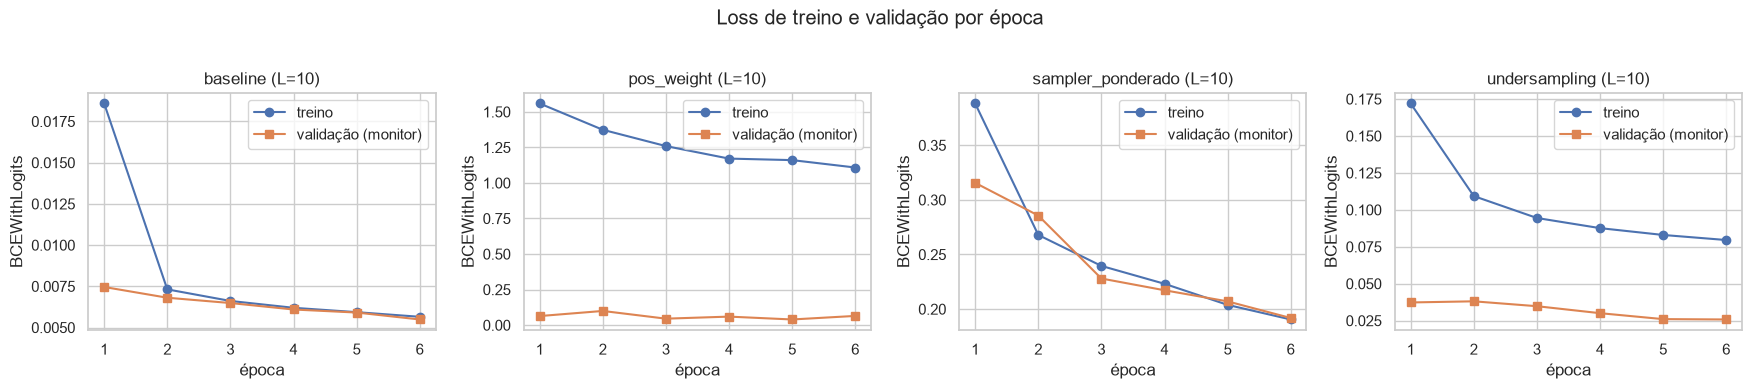

Estratégia escolhida (maior AP na validação): sampler_ponderado


In [16]:
def grafico_loss(chaves, titulo="Loss de treino e validação por época"):
    fig, axes = plt.subplots(1, len(chaves), figsize=(4.4 * len(chaves), 3.8), squeeze=False)
    for ax, c in zip(axes[0], chaves):
        h = resultados[c]["historico"]
        ax.plot(h["epoca"], h["loss_treino"], marker="o", label="treino")
        ax.plot(h["epoca"], h["loss_val"], marker="s", label="validação (monitor)")
        ax.set(title=f"{c[0]} (L={c[1]})", xlabel="época", ylabel="BCEWithLogits")
        ax.legend()
    plt.suptitle(titulo, y=1.02); plt.tight_layout(); plt.show()


def grafico_pr_validacao(chaves):
    fig = go.Figure()
    for c in chaves:
        p, r, thr = precision_recall_curve(y_val_full, resultados[c]["prob_val"])
        idx = np.unique(np.linspace(0, len(thr) - 1, min(1500, len(thr))).astype(int))
        fig.add_trace(go.Scatter(x=r[:-1][idx], y=p[:-1][idx], mode="lines", name=f"{c[0]} L={c[1]} (AP={resultados[c]['AP_val']:.3f})",
                                 customdata=thr[idx], hovertemplate="recall=%{x:.3f}<br>precisão=%{y:.3f}<br>limiar=%{customdata:.3f}<extra></extra>"))
    fig.add_hline(y=float(y_val_full.mean()), line_dash="dash", line_color="gray", annotation_text="sem habilidade")
    fig.update_layout(title="Curvas Precisão × Recall — validação completa", xaxis_title="Recall", yaxis_title="Precisão",
                      template="plotly_white", height=520)
    fig.show()


grafico_loss([(e, TAMANHO_REF) for e in ESTRATEGIAS])
grafico_pr_validacao([(e, TAMANHO_REF) for e in ESTRATEGIAS])

ESTRATEGIA_ESCOLHIDA = tab_estrategias.iloc[0]["estratégia"]          # 🧠 critério: maior AP na VALIDAÇÃO
print("Estratégia escolhida (maior AP na validação):", ESTRATEGIA_ESCOLHIDA)

**O que olhar / como interpretar**

* `loss_treino` **não é comparável** entre estratégias (pesos/amostras diferentes). Compare **AP na validação** e a curva PR.
* Se `loss_val` sobe enquanto `loss_treino` cai → sobreajuste (comum em `sampler_ponderado`, que repete positivos).
* Diferenças pequenas de AP entre estratégias podem estar dentro do ruído (≈ 1.400 positivos na validação; uma única semente).
  Para defender a escolha, repita com 2–3 sementes ou reporte intervalos (próximos passos).

## 13. Experimento B — tamanho da sequência (`L`) com a estratégia escolhida

`L = 1` é a **ablação sem histórico**: a rede vê apenas a transação-alvo. Comparar `L=1` com `L=5/10/20` responde à hipótese H1
(*o histórico acrescenta informação?*). Atenção: **mais histórico ≠ melhor** — janelas longas têm mais preenchimento e custam mais.


=== sampler_ponderado | L=1 | alvos de treino/época: 200,000 | positivos no pool: 6,764 | pos_weight=None
  época 1: loss treino=0.4875 | loss val=0.4509 | AP val(monitor)=0.0241 | 2s
  época 2: loss treino=0.3977 | loss val=0.4308 | AP val(monitor)=0.0166 | 2s
  época 3: loss treino=0.3787 | loss val=0.3805 | AP val(monitor)=0.0196 | 3s
  early stopping
  → VALIDAÇÃO COMPLETA: AP=0.0130 | melhor F1=0.0505 @ 0.9691 | recall≥80% → precisão=0.0048

=== sampler_ponderado | L=5 | alvos de treino/época: 200,000 | positivos no pool: 6,764 | pos_weight=None
  época 1: loss treino=0.4033 | loss val=0.3465 | AP val(monitor)=0.0431 | 3s
  época 2: loss treino=0.2862 | loss val=0.2919 | AP val(monitor)=0.0707 | 3s
  época 3: loss treino=0.2586 | loss val=0.2584 | AP val(monitor)=0.1084 | 3s
  época 4: loss treino=0.2447 | loss val=0.2457 | AP val(monitor)=0.1242 | 8s
  época 5: loss treino=0.2292 | loss val=0.2526 | AP val(monitor)=0.1467 | 8s
  época 6: loss treino=0.2189 | loss val=0.1923 | AP

,estratégia,L,AP_val,F1_val(melhor limiar),limiar_F1,precisão@recall≥80%,épocas
0,sampler_ponderado,1,0.0130,0.0505,0.9691,0.0048,3
1,sampler_ponderado,5,0.2075,0.2607,0.9966,0.0168,6
2,sampler_ponderado,10,0.2750,0.3206,0.9954,0.0208,6
3,sampler_ponderado,20,0.2334,0.2774,0.9953,0.0200,6


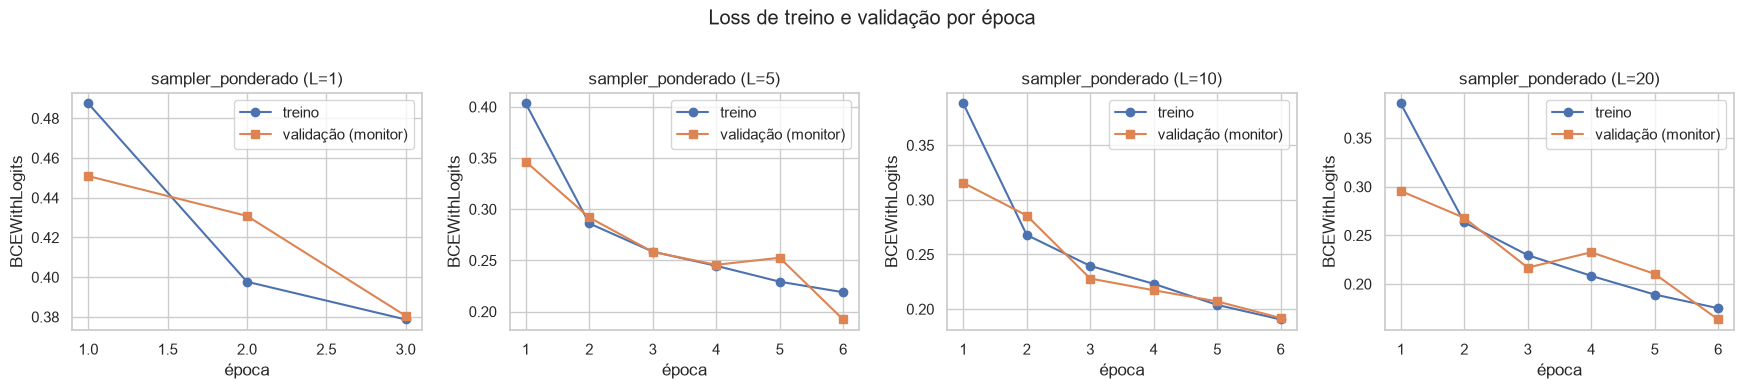

L escolhido (maior AP na validação): 10


In [17]:
for L_ in TAMANHOS:
    executar_experimento(ESTRATEGIA_ESCOLHIDA, L_)

tab_tamanhos = tabela_resultados([(ESTRATEGIA_ESCOLHIDA, L_) for L_ in TAMANHOS]).sort_values("L")
display(tab_tamanhos.round(4))

fig = px.bar(tab_tamanhos, x="L", y=["AP_val", "F1_val(melhor limiar)"], barmode="group", text_auto=".3f",
             title=f"Validação completa por tamanho de sequência ({ESTRATEGIA_ESCOLHIDA})",
             labels={"value": "métrica", "variable": ""})
fig.update_layout(template="plotly_white", xaxis=dict(type="category")); fig.show()
grafico_pr_validacao([(ESTRATEGIA_ESCOLHIDA, L_) for L_ in TAMANHOS])
grafico_loss([(ESTRATEGIA_ESCOLHIDA, L_) for L_ in TAMANHOS])

L_ESCOLHIDO = int(tab_tamanhos.sort_values("AP_val", ascending=False).iloc[0]["L"])
print("L escolhido (maior AP na validação):", L_ESCOLHIDO)

**Como interpretar:** se `L=1` empata com `L>1` (diferença menor que a variação entre sementes), **não** há evidência de que o histórico ajude *com estes atributos*.
Lembre que, nos modelos de árvore, parte do histórico já entrou como atributos manuais (`envios_anteriores_log`, `pares_anteriores_log`, …),
o que torna a comparação "LSTM vs LightGBM" uma comparação entre **duas formas de usar histórico**, não entre "com" e "sem" histórico.

## 14. Avaliação final — **uma única vez** no teste

Configuração congelada: estratégia e `L` escolhidos pela **validação**; limiar = melhor F1 **na validação**.
A função abaixo impede uma segunda avaliação (evita "olhar o teste" repetidamente).

In [18]:
_TESTE_AVALIADO = {"feito": False}


def avaliar_no_teste(chave, permitir_repetir=False):
    if _TESTE_AVALIADO["feito"] and not permitir_repetir:
        raise RuntimeError("O teste já foi avaliado. Repetir contamina a estimativa final.")
    _TESTE_AVALIADO["feito"] = True
    res = resultados[chave]
    modelo = ClassificadorLSTM(N_NUM_ENTRADA, cardinalidades).to(DISPOSITIVO)
    modelo.load_state_dict(res["estado"])
    prob, _ = prever_lstm(modelo, SequenciasSAML(ctx, alvos_teste, chave[1]))
    y_te = y_all[alvos_teste]
    out = metricas_binarias(y_te, prob, res["limiar_f1"])        # limiar da VALIDAÇÃO
    out.update({"prob": prob, "y": y_te, "cm": confusion_matrix(y_te, (prob >= res["limiar_f1"]).astype(int))})
    return out


CHAVE_FINAL = (ESTRATEGIA_ESCOLHIDA, L_ESCOLHIDO)
print("Configuração final:", CHAVE_FINAL, "| limiar (validação) =", round(resultados[CHAVE_FINAL]["limiar_f1"], 4))
teste = avaliar_no_teste(CHAVE_FINAL)

print(f"\nTESTE — LSTM {CHAVE_FINAL}")
print({k: round(v, 4) for k, v in teste.items() if k in ("accuracy", "precision", "recall", "f1", "AP", "limiar")})
print("\nMatriz de confusão [[TN FP],[FN TP]]:\n", teste["cm"])
print(classification_report(teste["y"], (teste["prob"] >= teste["limiar"]).astype(int), target_names=["normal", "lavagem"], digits=4, zero_division=0))

Configuração final: ('sampler_ponderado', 10) | limiar (validação) = 0.9954

TESTE — LSTM ('sampler_ponderado', 10)
{'accuracy': 0.9981, 'precision': 0.2879, 'recall': 0.3872, 'f1': 0.3302, 'AP': 0.2855, 'limiar': 0.9954}

Matriz de confusão [[TN FP],[FN TP]]:
 [[1422406    1625]
 [   1040     657]]
              precision    recall  f1-score   support

      normal     0.9993    0.9989    0.9991   1424031
     lavagem     0.2879    0.3872    0.3302      1697

    accuracy                         0.9981   1425728
   macro avg     0.6436    0.6930    0.6646   1425728
weighted avg     0.9984    0.9981    0.9983   1425728



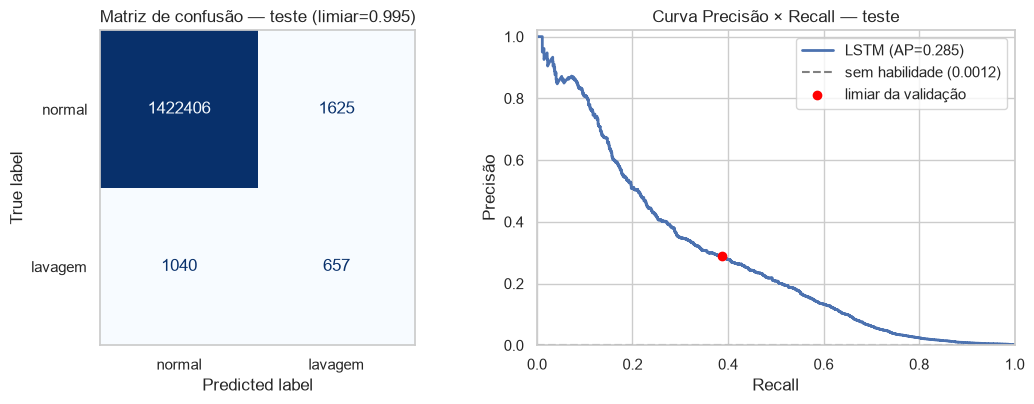

,mês,alvos,positivos,TP,FP,FN,precisão,recall,AP
0,2023-07,769146,867,330,786,537,0.2957,0.3806,0.2773
1,2023-08,656582,830,327,839,503,0.2804,0.3940,0.2934


In [19]:
# Gráficos do teste: matriz de confusão + curva PR (matplotlib) e PR interativa (plotly)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(teste["cm"], display_labels=["normal", "lavagem"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title(f"Matriz de confusão — teste (limiar={teste['limiar']:.3f})"); ax[0].grid(False)
p, r, thr = precision_recall_curve(teste["y"], teste["prob"])
ax[1].plot(r, p, lw=2, label=f"LSTM (AP={teste['AP']:.3f})")
ax[1].axhline(teste["y"].mean(), color="gray", ls="--", label=f"sem habilidade ({teste['y'].mean():.4f})")
ax[1].scatter([teste["recall"]], [teste["precision"]], color="red", zorder=5, label="limiar da validação")
ax[1].set(xlabel="Recall", ylabel="Precisão", title="Curva Precisão × Recall — teste", xlim=(0, 1), ylim=(0, 1.02)); ax[1].legend()
plt.tight_layout(); plt.show()


def metricas_por_mes(alvos, y_real, prob, limiar):
    # Resultados por período (mês): mostra a estabilidade e quantos positivos sustentam cada métrica.
    mes = dataset["Timestamp"].iloc[alvos].dt.to_period("M").astype(str).values
    linhas_ = []
    for m in sorted(set(mes)):
        s = mes == m
        pred = (prob[s] >= limiar).astype(int)
        tp = int(((pred == 1) & (y_real[s] == 1)).sum())
        fp = int(((pred == 1) & (y_real[s] == 0)).sum())
        fn = int(((pred == 0) & (y_real[s] == 1)).sum())
        linhas_.append({"mês": m, "alvos": int(s.sum()), "positivos": int(y_real[s].sum()), "TP": tp, "FP": fp, "FN": fn,
                        "precisão": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan,
                        "AP": average_precision_score(y_real[s], prob[s]) if y_real[s].sum() else np.nan})
    return pd.DataFrame(linhas_)


por_mes = metricas_por_mes(alvos_teste, teste["y"], teste["prob"], teste["limiar"])
display(por_mes.round(4))
fig = px.bar(por_mes.melt(id_vars=["mês", "positivos"], value_vars=["precisão", "recall", "AP"]), x="mês", y="value", color="variable",
             barmode="group", hover_data=["positivos"], title="Teste — métricas por mês (veja `positivos`: poucos casos → métrica instável)",
             labels={"value": "valor", "variable": ""})
fig.update_layout(template="plotly_white"); fig.show()

## 15. Comparação com os modelos tradicionais

**Valores de referência transcritos do `SAML-D.md`** (resultado final no teste, limiar escolhido na validação). Não foram recalculados aqui.

**Condições de comparabilidade (✅ conferidas / ⚠️ ressalvas):**

* ✅ mesmos registros-alvo e mesmas partições temporais (contagens conferidas na seção 5);
* ✅ limiar escolhido na validação e teste usado uma vez;
* ⚠️ os modelos de árvore foram treinados em uma amostra aleatória de 500 mil linhas com **atributos tabulares + agregados do passado**; a LSTM (estratégia `baseline`) usa a mesma amostra, mas recebe **uma janela de transações**;
* ⚠️ resultados de uma única execução/semente; diferenças pequenas não são conclusivas.

**Inconsistência registrada, não corrigida silenciosamente:** para a Regressão Logística, precisão = 0,480 e recall = 0,1131 dão F1 ≈ **0,1831**, mas o `SAML-D.md`
registra **0,01831**. A tabela mostra os dois valores (`F1_registrado` e `F1_recalculado`) — confira no notebook original.

In [20]:
ref = pd.DataFrame({
    "modelo": ["LightGBM", "RandomForest", "LogisticRegression", "DummyClassifier"],
    "accuracy": [0.9997, 0.9993, 0.9988, 0.9988],
    "precision": [0.901, 0.710, 0.480, 0.0],
    "recall": [0.8362, 0.7560, 0.1131, 0.0],
    "F1_registrado": [0.8674, 0.7323, 0.01831, 0.0],
    "AP": [0.9200, 0.7396, 0.1823, 0.0012],
}).set_index("modelo")
ref["F1_recalculado"] = 2 * ref["precision"] * ref["recall"] / (ref["precision"] + ref["recall"]).replace(0, np.nan)
ref["fonte"] = "SAML-D.md"

linha_lstm = pd.DataFrame({
    "accuracy": [teste["accuracy"]], "precision": [teste["precision"]], "recall": [teste["recall"]],
    "F1_registrado": [teste["f1"]], "AP": [teste["AP"]], "F1_recalculado": [teste["f1"]], "fonte": ["este notebook"]},
    index=[f"LSTM {CHAVE_FINAL[0]} L={CHAVE_FINAL[1]}"])
comparacao = pd.concat([ref, linha_lstm]).sort_values("AP", ascending=False)
display(comparacao.round(4))

longo = comparacao.reset_index().rename(columns={"index": "modelo"}).melt(
    id_vars="modelo", value_vars=["precision", "recall", "F1_recalculado", "AP"], var_name="métrica", value_name="valor")
fig = px.bar(longo, x="métrica", y="valor", color="modelo", barmode="group", text_auto=".3f",
             title="Teste — LSTM vs modelos tradicionais (F1 recalculado a partir de precisão e recall)")
fig.update_layout(template="plotly_white", height=520); fig.show()

,accuracy,precision,recall,F1_registrado,AP,F1_recalculado,fonte
LightGBM,0.9997,0.9010,0.8362,0.8674,0.9200,0.8674,SAML-D.md
RandomForest,0.9993,0.7100,0.7560,0.7323,0.7396,0.7323,SAML-D.md
LSTM sampler_ponderado L=10,0.9981,0.2879,0.3872,0.3302,0.2855,0.3302,este notebook
LogisticRegression,0.9988,0.4800,0.1131,0.0183,0.1823,0.1831,SAML-D.md
DummyClassifier,0.9988,0.0000,0.0000,0.0000,0.0012,NaN,SAML-D.md


**Como concluir sem exagerar**

* Se `AP(LSTM) < AP(LightGBM)`: resultado válido. Possíveis motivos (hipóteses, não conclusões): os agregados manuais do LightGBM (`pares_anteriores_log`, contagens totais do histórico)
  carregam informação além de `L ≤ 20` passos; a rede é pequena; poucos positivos no treino.
* Se `AP(LSTM) ≥ AP(LightGBM)`: antes de afirmar que "histórico ajuda", confira `L=1` vs `L>1` (seção 13) e repita com outras sementes.
* **Nunca** concluir que a LSTM é melhor "por ser rede neural".

## 16. Salvar artefatos (reprodutibilidade)

In [21]:
artefato = {
    "config": {"estrategia": CHAVE_FINAL[0], "L": CHAVE_FINAL[1], "hidden": HIDDEN, "n_camadas": N_CAMADAS, "dropout": DROPOUT,
               "emb_dim": EMB_DIM, "limiar": resultados[CHAVE_FINAL]["limiar_f1"], "semente": SEMENTE},
    "estado_modelo": resultados[CHAVE_FINAL]["estado"],
    "colunas_num": colunas_num_seq, "colunas_cat": colunas_cat_seq,
    "escalonador": escalonador, "vocabulario": {c: list(v) for c, v in vocab.items()}, "cardinalidades": cardinalidades,
}
joblib.dump(artefato, "lstm_saml_d_artefato.joblib")
print("Salvo: lstm_saml_d_artefato.joblib")

Salvo: lstm_saml_d_artefato.joblib


## 17. Limitações (declare na banca)

* **SAML-D é sintético:** bom desempenho **não** prova desempenho equivalente em bancos reais; o modelo pode aprender padrões artificiais do gerador.
* **A definição da sequência define o problema:** outra entidade (destinatário, par), outro `L` ou outro rótulo mudam a pergunta que a rede aprende.
* **Importância/atributos ≠ causalidade** e ≠ prova de lavagem. O modelo é uma **ferramenta de sinalização para análise humana**, não decisão automática de culpa.
* **Deriva temporal:** a taxa positiva do teste (0,119 %) é maior que a do treino (0,102 %); o desempenho pode variar por mês/entidade/tipo de pagamento (seção 14).
* **Ruído de avaliação:** ≈ 1.400–1.700 positivos por partição e uma semente; diferenças pequenas não são conclusivas.
* **Precision × recall dependem do custo operacional** de investigar um falso alerta versus deixar passar um caso.
* **Preenchimento e histórico curto:** contas novas têm janelas incompletas; o canal `mascara` informa isso à rede, mas há menos contexto.

## 18. Pontos a verificar nos materiais (não corrigidos silenciosamente)

1. **F1 da Regressão Logística no teste:** registrado 0,01831; precisão e recall registrados implicam ≈ 0,1831.
2. **`SAML-D.md` — matriz de confusão do Dummy (validação):** mostra `142` falsos negativos, mas o suporte da classe positiva é `1412`.
3. **`SAML-D.md` — acurácia da LR na CV:** aparece como `00.904815` (provável erro de digitação).
4. **`SAML-D.md` — tempos de CV:** as tabelas dos experimentos 1 e 2 repetem exatamente os mesmos tempos (66,6 s / 39,8 s / 8,4 s / 7,7 s); provável cópia.
5. **Seleção de modelo com o teste:** a versão inicial do `model_completo.ipynb` escolhia o "melhor modelo" pelo **PR-AUC do teste**; foi corrigido para usar a **validação**.
   Se você já usou a versão anterior, as métricas finais do teste continuam válidas (limiares vieram da validação), mas a escolha do modelo salvo deve ser refeita.

## 19. Comparação com os notebooks dos colegas (preencher)

Os notebooks dos colegas **não foram fornecidos** para esta análise; a tabela abaixo é um gabarito para você completar antes de integrar no repositório da equipe.

| Aspecto | Este notebook | Colega 1 | Colega 2 |
|---|---|---|---|
| Entidade que agrupa | `Sender_account` | ? | ? |
| Ordenação | `Timestamp` estável | ? | ? |
| Rótulo da sequência | última transação | ? | ? |
| Tamanho(s) da janela | 1 · 5 · 10 · 20 | ? | ? |
| Partições | 70/15/15 temporal (= árvores) | ? | ? |
| Pré-processamento | scaler + vocabulário só no treino; embeddings | ? | ? |
| Balanceamento | 4 estratégias comparadas, só no treino | ? | ? |
| Arquitetura / loss | LSTM 1×64 + `BCEWithLogitsLoss` | ? | ? |
| Limiar | melhor F1 na validação | ? | ? |
| Riscos de leakage observados | — | ? | ? |

## 20. Checklist de qualidade

- [x] Colunas, timestamps, IDs e alvo inspecionados (seções 2–3)
- [x] Agrupamento e ordenação justificados (seção 4)
- [x] Rótulo da sequência explícito: **última transação**
- [x] Tamanho da sequência tratado como hipótese (L = 1, 5, 10, 20)
- [x] `Is_laundering` fora dos atributos (`assert` na seção 6; rótulos do histórico também não usados)
- [x] Sem informação futura (`verificar_sequencias`, seção 7.1)
- [x] Mesmo registro-alvo em uma única partição (seção 5/7.1)
- [x] Scaler e vocabulário ajustados só no treino (seção 6)
- [x] Balanceamento só no treino; validação/teste naturais (seção 11–12)
- [x] Avaliação temporal justificada (partições cronológicas + métricas por mês)
- [x] Precision, recall, F1, AP e matriz de confusão (seção 14)
- [x] Limiar escolhido na validação e teste avaliado uma vez (`avaliar_no_teste`)
- [ ] Comparação com baselines **justa** — depende de você conferir as ressalvas da seção 15
- [x] Gráficos com interpretação textual
- [x] Limitações do dataset sintético explícitas (seção 17)
- [ ] **Consigo explicar e defender o código** — releia as seções 4, 7 e 10 e tente explicar cada dimensão em voz alta